<img src="https://full-stack-assets.s3.eu-west-3.amazonaws.com/M03-EDA/Tinder-Symbole.png" width="600">

# Speed Dating Analysis

## Business Question
**What drives a match?**

This notebook uses data from real speed dating experiments to investigate what actually drives attraction. Participants met face-to-face in four-minute dates, rated each other on six attributes, and decided whether they'd want to meet again. They also completed surveys about what they thought they were looking for.
The central question: what actually drives peoples decisions and does that differ by gender?

This notebook explores:
- Match rates and decision patterns
- Actual drivers of attraction by gender
- Differences between stated preferences and reality


# 1 - Setup

### A - Imports

In [1]:
# -----------------------------------------------------------------------------
# Imports
# -----------------------------------------------------------------------------

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import plotly.graph_objects as go

# Statistics
from scipy.stats import (mannwhitneyu, 
                         chi2_contingency, 
                         shapiro
                         )

# Data prediction
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, 
                             precision_score, 
                             confusion_matrix, 
                             recall_score, 
                             f1_score, 
                             )

### B - Settings

In [2]:
# -----------------------------------------------------------------------------
# FILE PATH
# -----------------------------------------------------------------------------
file = 'Speed+Dating+Data.csv'


# -----------------------------------------------------------------------------
# COLORS
# -----------------------------------------------------------------------------
palette = ['#345fff', '#e142d5', '#ff4b9b', 
           '#ffc352', '#f9f871', '#9bde7e', 
           '#4bbc8e', '#039590', '#1c6e7d', '#2f4858', ]
colors_sex  = ['#FF94FFFF', '#003CFF']
colors_3cat =['#249615'] + colors_sex
decision_colors = {0: '#00DFCD', 1: '#E63946'}

sns.set_theme(style="darkgrid", palette=palette)

### C - Functions definitions

In [3]:
# -----------------------------------------------------------------------------
# READ FILE
# -----------------------------------------------------------------------------
def read_file_safe(file_path: str) -> pd.DataFrame:
    '''Try several encoding to read a CSV file'''
    encodings = ['utf-16', 'utf-8', 'latin1']                           # Try several encodings in case of error
    for encoding in encodings:
        try:
            df = pd.read_csv(file_path, encoding=encoding)
            print(f"✓ Successfully read with {encoding}")
            print(f'Loaded {df.shape[0]} rows, {df.shape[1]} columns')   
            print(f'Columns: {list(df.columns)}') 
            return df
        except FileNotFoundError:
            raise FileNotFoundError(f"File '{file_path}' not found.")   # Return an error if file is not found


        except UnicodeDecodeError:                                      # Return an error if loading fails
            print(f"Failed with {encoding}")
            continue                                                    # Load next encoding if there's still left
    raise ValueError(f"Could not read {file_path} with any encoding")   # Return ValueError if all encodings failed


# -----------------------------------------------------------------------------
# NORMALIZE COLUMNS NAMES
# -----------------------------------------------------------------------------
def normalize_cols(df: pd.DataFrame) -> pd.DataFrame:
    '''Normalize columns name: lower char, remove spaces/special chars'''
    df.columns = (
        df.columns.str.lower()
                    .str.replace(r'[^a-z0-9]+', '_', regex=True) # 1 or more (+) chars that are not (^) a-z or 0-9
                    .str.strip('_')
    )
    return df


# -----------------------------------------------------------------------------
# NORMALIZE VALUES BETWEEN A SET OF COLUMNS
# -----------------------------------------------------------------------------
def normalization(df: pd.DataFrame, columns_list: list) -> pd.DataFrame:
    '''
    Take a list of columns and normalize rating values 
    between each columns so all studied waves become comparable
    '''
    df = df.copy()
    row_sum = df[columns_list].sum(axis=1).replace(0, np.nan) # Sum the values of all columns in argument and replace sum = 0 with nan
    for column in columns_list:
        # Get the % of importance for each column and scale everything to that
        df.loc[:, column] = df.loc[:, column].div(row_sum, axis=0)
    print(f'✓ Successfully scaled {columns_list}')
    return df


# -----------------------------------------------------------------------------
# CALCULATE COHEN'S D 
# -----------------------------------------------------------------------------
def cohen_d_calc(group1: pd.Series, group2: pd.Series) -> float:
    '''Calculate Cohen's d for two independent samples'''
    mean1, mean2 = np.mean(group1), np.mean(group2)
    std1, std2 = np.std(group1, ddof=1), np.std(group2, ddof=1)
    n1, n2 = len(group1), len(group2)
    s_pooled = np.sqrt((((n1 - 1) * std1 ** 2) + ((n2 - 1) * std2 ** 2)) / (n1 + n2 - 2))
    return (mean1 - mean2) / s_pooled


# -----------------------------------------------------------------------------
# GET ML SCORES, FEATURES IMPORTANCE AND CONFUSION MATRIX
# -----------------------------------------------------------------------------
def model_report(Y_train: pd.Series, 
                 Y_test: pd.Series, 
                 Y_train_pred: np.ndarray, 
                 Y_test_pred: np.ndarray, 
                 model: LogisticRegression | str, 
                 preprocessor: ColumnTransformer | None, 
                 gender: str) -> tuple[pd.DataFrame, pd.DataFrame | None, dict]:
    '''Build metrics, feature importance and confusion matrices from model predictions'''

    # Metrics dataframe
    metrics = pd.DataFrame({
        'gender':       gender,
        'set':          ['train', 
                         'test'],
        'accuracy':     [accuracy_score(Y_train, Y_train_pred),
                        accuracy_score(Y_test,  Y_test_pred)],
        'precision':    [precision_score(Y_train, Y_train_pred, average='macro', zero_division=0),
                        precision_score(Y_test,  Y_test_pred,  average='macro', zero_division=0)],
        'recall':       [recall_score(Y_train, Y_train_pred, average='macro', zero_division=0),
                        recall_score(Y_test,  Y_test_pred,  average='macro', zero_division=0)],
        'f1-score':     [f1_score(Y_train, Y_train_pred, average='macro', zero_division=0),
                        f1_score(Y_test,  Y_test_pred,  average='macro', zero_division=0)],
    })

    # Feature importance dataframe
    if isinstance(model, str):  # If it's the dummy model that has no features, return None, otherwise return features
        features = None
    else:
        feature_names = preprocessor.get_feature_names_out()    # type: ignore
        features = pd.DataFrame({
            'gender':       gender,
            'feature':      feature_names,
            'coefficient':  model.coef_[0]
        })

    # Confusion matrix
    conf_matrix = {
        'train': confusion_matrix(Y_train, Y_train_pred),
        'test':  confusion_matrix(Y_test,  Y_test_pred)
    }

    return metrics, features, conf_matrix

The read_file_safe function allows to properly read the csv file, regardless of encoding.

The questions asked between waves differs in term of rating:
The normalization function is defined to scale everything in percentage to make waves comparable.

The model_report function allows to get all metrics from our machine learning model in one place, in one step.

### D - Key dataset points

| Column | Description | Details / Values |
| :--- | :--- | :--- |
| **Event Context** | | |
| `wave` | Wave number (experiment date) | 1–21 |
| `position` | Station number where partner was met | 1–N |
| `positin1` | Starting station number | 1–N |
| `order` | Date order that night | 1st, 2nd, etc. |
| **Partner & Match Data** | | |
| `dec` | Person's decision on event night | Yes/No |
| `dec_o` | Partner's decision on event night | Yes/No |
| `match` | Did they match? | 1=Yes, 0=No |
| `int_corr` | Correlation of interests (Time 1 vs Partner) | Float |
| `age` | Age of person | Years |
| `age_o` | Age of partner | Years |
| `pf_o_att` | Partner's stated preference (Time 1) | Points (0-100) |
| `gender` | Person's gender | Female=0, Male=1 |
| **6 Metrics** | | |
| `attr` | Attractiveness | Core attribute |
| `sinc` | Sincerity | Core attribute |
| `intel` | Intelligence | Core attribute |
| `fun` | Fun | Core attribute |
| `amb` | Ambition | Core attribute |
| `shar` | Shared interests/hobbies | Core attribute |
| **7 Key Questions** | | |
| `1` | What do you look for in the opposite sex? | What self want |
| `2` | What do you think the opposite sex looks for? | What self think other sex want |
| `3` | Rate your opinion of your own attributes? | Self-rating scale |
| `4` | What MOST fellow men/women look for? | Perception scale |
| `5` | How do others perceive you? | Perceived rating |
| `7` | Actual importance in decisions? | Decision weights |
| **Timeline Suffixes** | Variables examples | Timing |
| `_1` | `attr1_1` | Before date |
| `_o` | `attr_o` | Partner's rating just after date |
| `no suffix` | `attr` | Person's rating just after date |
| `_s` | `attr1_s` | Half through the date night |
| `_2` | `attr1_2` | The day after date |
| `_3` | `attr1_3` | 3-4 weeks after date |


> **Scale Note:** Variables use **100-point allocation** (Waves 1-5, 10-21) or **1-10 scale** (Waves 6-9).

# 2 - Data loading and cleaning

### A - Loading

In [4]:
# -----------------------------------------------------------------------------
# Load and read data from files
# -----------------------------------------------------------------------------
print('\n' + '-'*80)
print('PART 1: LOADING DATASETS')
print('-'*80)
print()


tinder_df_raw = read_file_safe(file)
tinder_df_raw = normalize_cols(tinder_df_raw)


--------------------------------------------------------------------------------
PART 1: LOADING DATASETS
--------------------------------------------------------------------------------

Failed with utf-16
Failed with utf-8
✓ Successfully read with latin1
Loaded 8378 rows, 195 columns
Columns: ['iid', 'id', 'gender', 'idg', 'condtn', 'wave', 'round', 'position', 'positin1', 'order', 'partner', 'pid', 'match', 'int_corr', 'samerace', 'age_o', 'race_o', 'pf_o_att', 'pf_o_sin', 'pf_o_int', 'pf_o_fun', 'pf_o_amb', 'pf_o_sha', 'dec_o', 'attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o', 'like_o', 'prob_o', 'met_o', 'age', 'field', 'field_cd', 'undergra', 'mn_sat', 'tuition', 'race', 'imprace', 'imprelig', 'from', 'zipcode', 'income', 'goal', 'date', 'go_out', 'career', 'career_c', 'sports', 'tvsports', 'exercise', 'dining', 'museums', 'art', 'hiking', 'gaming', 'clubbing', 'reading', 'tv', 'theater', 'movies', 'concerts', 'music', 'shopping', 'yoga', 'exphappy', 'expnum', 'attr1_1'

In [5]:
# -----------------------------------------------------------------------------
# CHECK FOR DUPLICATED DATA
# -----------------------------------------------------------------------------
print('\n' + '-'*80)
print('QUICK ANALYSIS')
print('-'*80)
print()

print("Duplicated lines: ")
print(f'There are {tinder_df_raw.duplicated().sum()} duplicated lines')


# -----------------------------------------------------------------------------
# DATA ANALYSIS: SHAPE
# -----------------------------------------------------------------------------
print()
print("Shape: ")
print(f"There's {tinder_df_raw.shape[0]} rows and {tinder_df_raw.shape[1]} columns")
print()


# -----------------------------------------------------------------------------
# DATA ANALYSIS: HEAD ON ALL COLUMNS
# -----------------------------------------------------------------------------
print()
print("Dataset Preview: ")
pd.set_option('display.max_columns', None)
display(tinder_df_raw.head())


# -----------------------------------------------------------------------------
# DATA ANALYSIS: DESCRIBE ON ALL COLUMNS
# -----------------------------------------------------------------------------
print()
print("Dataset Statistics: ")
display(tinder_df_raw.describe(include='all'))
pd.reset_option("display.max_columns")


--------------------------------------------------------------------------------
QUICK ANALYSIS
--------------------------------------------------------------------------------

Duplicated lines: 
There are 0 duplicated lines

Shape: 
There's 8378 rows and 195 columns


Dataset Preview: 


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,sinc_o,intel_o,fun_o,amb_o,shar_o,like_o,prob_o,met_o,age,field,field_cd,undergra,mn_sat,tuition,race,imprace,imprelig,from,zipcode,income,goal,date,go_out,career,career_c,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,exphappy,expnum,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1,attr4_1,sinc4_1,intel4_1,fun4_1,amb4_1,shar4_1,attr2_1,sinc2_1,intel2_1,fun2_1,amb2_1,shar2_1,attr3_1,sinc3_1,fun3_1,intel3_1,amb3_1,attr5_1,sinc5_1,intel5_1,fun5_1,amb5_1,dec,attr,sinc,intel,fun,amb,shar,like,prob,met,match_es,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s,attr3_s,sinc3_s,intel3_s,fun3_s,amb3_s,satis_2,length,numdat_2,attr7_2,sinc7_2,intel7_2,fun7_2,amb7_2,shar7_2,attr1_2,sinc1_2,intel1_2,fun1_2,amb1_2,shar1_2,attr4_2,sinc4_2,intel4_2,fun4_2,amb4_2,shar4_2,attr2_2,sinc2_2,intel2_2,fun2_2,amb2_2,shar2_2,attr3_2,sinc3_2,intel3_2,fun3_2,amb3_2,attr5_2,sinc5_2,intel5_2,fun5_2,amb5_2,you_call,them_cal,date_3,numdat_3,num_in_3,attr1_3,sinc1_3,intel1_3,fun1_3,amb1_3,shar1_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,27.0,2.0,35.0,20.0,20.0,20.0,0.0,5.0,0,6.0,8.0,8.0,8.0,8.0,6.0,7.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,6.0,9.0,7.0,7.0,6.0,5.0,7.0,6.0,2.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,22.0,2.0,60.0,0.0,0.0,40.0,0.0,0.0,0,7.0,8.0,10.0,7.0,7.0,5.0,8.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,7.0,8.0,7.0,8.0,5.0,6.0,7.0,5.0,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,22.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,1,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,1.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,5.0,8.0,9.0,8.0,5.0,7.0,7.0,NaN,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,23.0,2.0,30.0,5.0,15.0,40.0,5.0,5.0,1,7.0,8.0,9.0,8.0,9


Dataset Statistics: 


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,sinc_o,intel_o,fun_o,amb_o,shar_o,like_o,prob_o,met_o,age,field,field_cd,undergra,mn_sat,tuition,race,imprace,imprelig,from,zipcode,income,goal,date,go_out,career,career_c,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,exphappy,expnum,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1,attr4_1,sinc4_1,intel4_1,fun4_1,amb4_1,shar4_1,attr2_1,sinc2_1,intel2_1,fun2_1,amb2_1,shar2_1,attr3_1,sinc3_1,fun3_1,intel3_1,amb3_1,attr5_1,sinc5_1,intel5_1,fun5_1,amb5_1,dec,attr,sinc,intel,fun,amb,shar,like,prob,met,match_es,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s,attr3_s,sinc3_s,intel3_s,fun3_s,amb3_s,satis_2,length,numdat_2,attr7_2,sinc7_2,intel7_2,fun7_2,amb7_2,shar7_2,attr1_2,sinc1_2,intel1_2,fun1_2,amb1_2,shar1_2,attr4_2,sinc4_2,intel4_2,fun4_2,amb4_2,shar4_2,attr2_2,sinc2_2,intel2_2,fun2_2,amb2_2,shar2_2,attr3_2,sinc3_2,intel3_2,fun3_2,amb3_2,attr5_2,sinc5_2,intel5_2,fun5_2,amb5_2,you_call,them_cal,date_3,numdat_3,num_in_3,attr1_3,sinc1_3,intel1_3,fun1_3,amb1_3,shar1_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
count,8378.000000,8377.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,6532.000000,8378.000000,8378.000000,8368.000000,8378.000000,8220.000000,8378.000000,8274.000000,8305.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8378.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8128.000000,8060.000000,7993.000000,8283.000000,8315,8296.000000,4914,3133,3583,8315.000000,8299.000000,8299.000000,8299,7314,4279,8299.000000,8281.000000,8299.000000,8289,8240.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8277.000000,1800.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,6489.000000,6489.000000,6489.000000,6489.000000,6489.000000,6467.000000,8299.000000,8299.000000,8299.000000,8299.000000,8289.000000,8289.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,4906.000000,4906.000000,4906.000000,4906.000000,4906.000000,8378.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8138.000000,8069.000000,8003.000000,7205.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4000.00000,4000.000000,4000.000000,4000.000000,4000.000000,7463.000000,7463.000000,7433.000000,1984.000000,1955.000000,1984.000000,1984.000000,1955.000000,1974.000000,7445.000000,7463.000000,7463.000000,7463.000000,7463.000000,7463.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.00000,5775.000000,5775.000000,5775.000000,5775.000000,7463.000000,7463.000000,7463.000000,7463.000000,7463.000000,4377.000000,4377.000000,4377.000000,4377.000000,4377.000000,3974.000000,3974.000000,3974.000000,1496.000000,668.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2016.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,259,NaN,241,68,115,NaN,NaN,NaN,269,409,261,NaN,NaN,NaN,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

### B - Missing data and types

In [6]:
# -----------------------------------------------------------------------------
# DATASET
# -----------------------------------------------------------------------------
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
print('\n' + '-'*80)
print('MISSING DATA AND TYPES')
print('-'*80)
missing_values_pct =  (100 * tinder_df_raw.isna().sum() / tinder_df_raw.shape[0]).round(2)      # Get all missing data percentage
missing_values_df = missing_values_pct.sort_values(ascending=False).to_frame(name='missing_%')  # Create a dataframe from the serie
dtype_df = tinder_df_raw.dtypes.to_frame(name='dtype')                                          # Dataframe of type value

infotypes_df = missing_values_df.merge(dtype_df, left_index=True, right_index=True)             # Merge both dataframe to get all result
display(infotypes_df)

# Reset display options
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')


--------------------------------------------------------------------------------
MISSING DATA AND TYPES
--------------------------------------------------------------------------------


,missing_%,dtype
num_in_3,92.03,float64
numdat_3,82.14,float64
expnum,78.52,float64
sinc7_2,76.67,float64
amb7_2,76.67,float64
shar7_2,76.44,float64
attr7_2,76.32,float64
fun7_2,76.32,float64
intel7_2,76.32,float64
fun5_3,75.94,float64


There's a lot of missing values in the dataset !

For analysis and machine learning, we plan to use:
- dec (`0%` missing)
- match (`0%` missing)
- all attributes 1_1 (around `1%` missing)
- pure metrics like attr and sinc (`2%-13%` missing)

We'll take action when needed: we'll avoid lackluster columns.
Next, let's take a look and focus at our key ML columns.

### C - Focus on missing data from key columns for ML

In [7]:
# -----------------------------------------------------------------------------
# MISSING DATA FOR ML ANALYSIS
# -----------------------------------------------------------------------------
rating_cols = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar'] # Selecting all columns that'll be use in our ML
display(infotypes_df.loc[rating_cols])

rating_rows_missing_data = tinder_df_raw[rating_cols].isna().any(axis=1) # If one of the rating columns value is missing, return True
missing_rows = rating_rows_missing_data.sum()
total_rows = len(tinder_df_raw)
pct_missing = missing_rows / total_rows * 100

yes_rate_missing = tinder_df_raw.loc[rating_rows_missing_data, 'dec'].mean()
yes_rate_not_missing   = tinder_df_raw.loc[~rating_rows_missing_data, 'dec'].mean()

print(f"Total rows:                     {total_rows:}")
print(f"Missing rows:                   {missing_rows:}  ({pct_missing:.1f}%)")
print(f"Complete rows:                  {total_rows - missing_rows:}  ({100 - pct_missing:.1f}%)")
print(f"\n'Yes' rate in missing rows:     {yes_rate_missing*100:.1f}%")
print(f"'Yes' rate in complete rows:    {yes_rate_not_missing*100:.1f}%")
print(f"Difference:                     {abs(yes_rate_not_missing - yes_rate_missing)*100:.1f} points")

,missing_%,dtype
attr,2.41,float64
sinc,3.31,float64
intel,3.53,float64
fun,4.18,float64
amb,8.50,float64
shar,12.74,float64


Total rows:                     8378
Missing rows:                   1338  (16.0%)
Complete rows:                  7040  (84.0%)

'Yes' rate in missing rows:     36.0%
'Yes' rate in complete rows:    43.1%
Difference:                     7.1 points


The 'yes' rate in rows with missing values (`36.0%`) is noticeably lower than in complete rows (`43.1%`).

### D - Columns classification

In [8]:
# -----------------------------------------------------------------------------
# CLASSIFICATION OF COLUMNS DEDICATED TO RATING
# -----------------------------------------------------------------------------
# Drop
partner_stated_pref = ['pf_o_att', 'pf_o_sin', 'pf_o_int', 'pf_o_fun', 'pf_o_amb', 'pf_o_sha']

# Keep and normalize
before_date_ratings_1 = ['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']

# Drop
before_date_ratings_2 = ['attr2_1', 'sinc2_1', 'intel2_1', 'fun2_1', 'amb2_1', 'shar2_1']
before_date_ratings_3 = ['attr3_1', 'sinc3_1', 'fun3_1', 'intel3_1', 'amb3_1']
before_date_ratings_4 = ['attr4_1', 'sinc4_1', 'intel4_1', 'fun4_1', 'amb4_1', 'shar4_1']
before_date_ratings_5 = ['attr5_1', 'sinc5_1', 'intel5_1', 'fun5_1', 'amb5_1']

# Drop
half_through_evening_ratings1 = ['attr1_s', 'sinc1_s', 'intel1_s', 'fun1_s', 'amb1_s', 'shar1_s']
half_through_evening_ratings3 = ['attr3_s', 'sinc3_s', 'intel3_s', 'fun3_s', 'amb3_s']

# Keep and normalize
atfer_1_day_date_ratings1 = ['attr1_2', 'sinc1_2', 'intel1_2', 'fun1_2', 'amb1_2', 'shar1_2']
atfer_1_day_date_ratings7 = ['attr7_2', 'sinc7_2', 'intel7_2', 'fun7_2', 'amb7_2', 'shar7_2']

# Drop
atfer_1_day_date_ratings2 = ['attr2_2', 'sinc2_2', 'intel2_2', 'fun2_2', 'amb2_2', 'shar2_2']
atfer_1_day_date_ratings3 = ['attr3_2', 'sinc3_2', 'intel3_2', 'fun3_2', 'amb3_2']
atfer_1_day_date_ratings4 = ['attr4_2', 'sinc4_2', 'intel4_2', 'fun4_2', 'amb4_2', 'shar4_2']
atfer_1_day_date_ratings5 = ['attr5_2', 'sinc5_2', 'intel5_2', 'fun5_2', 'amb5_2']

# Keep and normalize
after_4_weeks_date_ratings1 = ['attr1_3', 'sinc1_3', 'intel1_3', 'fun1_3', 'amb1_3', 'shar1_3']
after_4_weeks_date_ratings7 = ['attr7_3', 'sinc7_3', 'intel7_3', 'fun7_3', 'amb7_3', 'shar7_3']

# Drop
after_4_weeks_date_ratings2 = ['attr2_3', 'sinc2_3', 'intel2_3', 'fun2_3', 'amb2_3', 'shar2_3']
after_4_weeks_date_ratings3 = ['attr3_3', 'sinc3_3', 'intel3_3', 'fun3_3', 'amb3_3']
after_4_weeks_date_ratings4 = ['attr4_3', 'sinc4_3', 'intel4_3', 'fun4_3', 'amb4_3', 'shar4_3']
after_4_weeks_date_ratings5 = ['attr5_3', 'sinc5_3', 'intel5_3', 'fun5_3', 'amb5_3']

columns_list_to_norm = [
    before_date_ratings_1, 
    atfer_1_day_date_ratings1, 
    atfer_1_day_date_ratings7, 
    after_4_weeks_date_ratings1, 
    after_4_weeks_date_ratings7
]

In [9]:
# -----------------------------------------------------------------------------
# CLASSIFICATION OF COLUMNS TO DROP
# -----------------------------------------------------------------------------
drop_other_col = [
            'idg', 'condtn', 'position', 'positin1', 'field', 'field_cd', 
            'undergra', 'mn_sat', 'tuition', 'race', 'imprace', 'imprelig', 
            'from', 'zipcode', 'income', 'goal', 'date', 'go_out', 'career', 
            'career_c', 'sports', 'tvsports', 'exercise', 'dining', 'museums', 
            'art', 'hiking', 'gaming', 'clubbing', 'reading', 'tv', 'theater', 
            'movies', 'concerts', 'music', 'shopping', 'yoga', 'exphappy', 
            'expnum', 'match_es', 'you_call', 'them_cal', 'date_3', 'numdat_3', 'num_in_3',
            'round', 'partner', 'int_corr', 'samerace', 'satis_2', 'length', 'numdat_2'
            ]

drop_col =  partner_stated_pref + before_date_ratings_2 + before_date_ratings_3 + \
            before_date_ratings_4 + before_date_ratings_5 + half_through_evening_ratings1 + \
            half_through_evening_ratings3 + atfer_1_day_date_ratings2 + atfer_1_day_date_ratings3 + \
            atfer_1_day_date_ratings4 + atfer_1_day_date_ratings5 + after_4_weeks_date_ratings2 + \
            after_4_weeks_date_ratings3 + after_4_weeks_date_ratings4 + after_4_weeks_date_ratings5
            
# Gather all columns to be droped
drop_col = drop_other_col + drop_col

In [10]:
# -----------------------------------------------------------------------------
# USEFULL COLUMNS TO KEEP BUT NOT TO SCALE
# -----------------------------------------------------------------------------
after_date_rating = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar', 'like']         # No difference between waves: 1-10 rating
partner_rating_person = ['attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o'] # No difference between waves: 1-10 rating
partner_rating_likeliness = ['like_o', 'prob_o']
matching = ['match', 'dec_o', 'dec']
other = ['id', 'pid', 'order']

### E - Dataframe modifications

We need to normalize results since all waves didn't answer the same way:

In [11]:
# -----------------------------------------------------------------------------
# DROPING COLUMNS
# -----------------------------------------------------------------------------
tinder_df_normalized = tinder_df_raw.copy()
tinder_df_normalized.drop(columns=drop_col, inplace=True)

# -----------------------------------------------------------------------------
# RATINGS COLUMNS NORMALIZATION
# -----------------------------------------------------------------------------
for column_list in columns_list_to_norm:
    tinder_df_normalized = normalization(tinder_df_normalized, column_list)
print('✓ Job done !')

✓ Successfully scaled ['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']
✓ Successfully scaled ['attr1_2', 'sinc1_2', 'intel1_2', 'fun1_2', 'amb1_2', 'shar1_2']
✓ Successfully scaled ['attr7_2', 'sinc7_2', 'intel7_2', 'fun7_2', 'amb7_2', 'shar7_2']
✓ Successfully scaled ['attr1_3', 'sinc1_3', 'intel1_3', 'fun1_3', 'amb1_3', 'shar1_3']
✓ Successfully scaled ['attr7_3', 'sinc7_3', 'intel7_3', 'fun7_3', 'amb7_3', 'shar7_3']
✓ Job done !


In [12]:
# -----------------------------------------------------------------------------
# CHECKING NORMALIZATION WITH SAMPLES
# -----------------------------------------------------------------------------
for column_list in columns_list_to_norm:
    print(f'\n{tinder_df_normalized[column_list].dropna().sample(2)}')


      attr1_1  sinc1_1  intel1_1  fun1_1  amb1_1  shar1_1
6628     0.15     0.15      0.18    0.18    0.14      0.2
7039     0.20     0.20      0.20    0.15    0.15      0.1

       attr1_2   sinc1_2  intel1_2    fun1_2    amb1_2   shar1_2
3127  0.195120  0.122012  0.170717  0.195120  0.146315  0.170717
3390  0.133287  0.222178  0.155584  0.177782  0.155584  0.155584

      attr7_2  sinc7_2  intel7_2  fun7_2  amb7_2  shar7_2
8040      0.3      0.1       0.2    0.15     0.0     0.25
7249      0.5      0.1       0.1    0.15     0.0     0.15

      attr1_3  sinc1_3  intel1_3  fun1_3  amb1_3  shar1_3
1061     0.18     0.18      0.15    0.14    0.15     0.20
4129     0.15     0.15      0.20    0.20    0.15     0.15

      attr7_3  sinc7_3  intel7_3  fun7_3  amb7_3  shar7_3
5109      0.5     0.05       0.1     0.2     0.1     0.05
4024      0.6     0.05       0.2     0.1     0.0     0.05


# 3 - Explanatory data analysis

### A - Sex

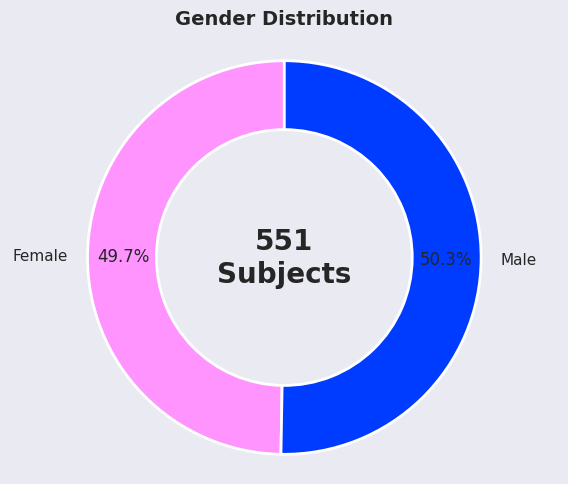

In [13]:
# -----------------------------------------------------------------------------
# GENDER DISTRIBUTION
# -----------------------------------------------------------------------------
gender_dict = {0: 'Female', 1: 'Male'}

tinder_df_sex = tinder_df_normalized.drop_duplicates(subset='iid').copy()
tinder_df_sex = (tinder_df_sex
                  .groupby('gender')
                  .agg(total=('gender', 'count'))
                  .reset_index()
                )
tinder_df_sex['gender'] = tinder_df_sex['gender'].map(gender_dict) # For more readable legend

fig, ax = plt.subplots(figsize=(6, 5))

fig.patch.set_facecolor('#EAEAF2')        # Change background color to match seaborn darkgrid
ax.pie(tinder_df_sex['total'], 
        labels=list(tinder_df_sex['gender']),
        startangle=90, 
        autopct='%1.1f%%',
        colors=colors_sex,
        pctdistance=0.82,                   # Move percentage into the donut chart
        wedgeprops={'width': 0.35, 'edgecolor': 'white', 'linewidth': 2}
        )

ax.text(
    0, 0,
    f'{tinder_df_sex['total'].sum()}\nSubjects',
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold'
)

ax.set_title('Gender Distribution', fontsize=14, fontweight='bold', y=1.02)
ax.axis('equal')
plt.tight_layout()  # Adjust spacing
plt.show()

The dataset is balanced, which is expected if you want to run such an experimentation.

### B - Age

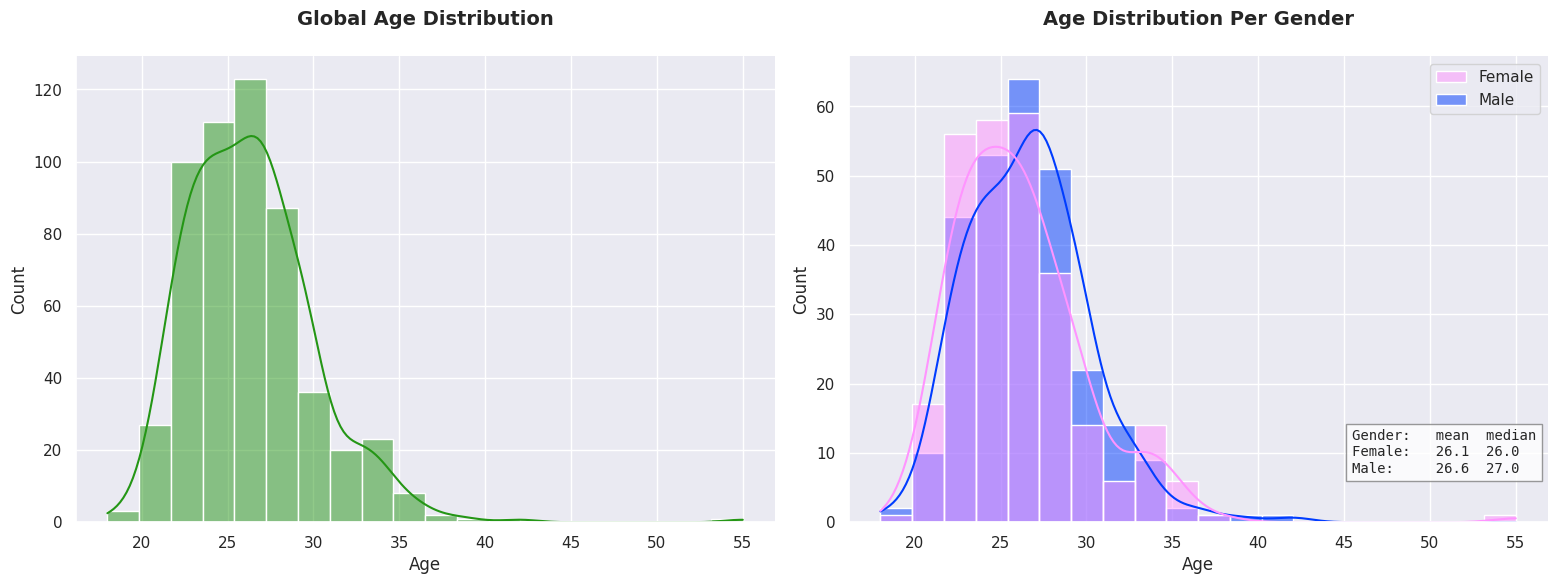

In [14]:
# -----------------------------------------------------------------------------
# AGE DISTRIBUTION
# -----------------------------------------------------------------------------
tinder_df_age = (tinder_df_normalized
                    .groupby('iid')
                    .agg(
                        gender=('gender', 'first'),
                        age=('age','first'))
                    .reset_index()
                )
tinder_df_age['gender'] = tinder_df_age['gender'].map(gender_dict) # For more readable legend


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# General Age Distribution
sns.histplot(data=tinder_df_age, 
             x='age', 
             bins=20, 
             kde=True, 
             color=colors_3cat[0], 
             alpha=0.5,
             ax=axes[0],
)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')
axes[0].set_title('Global Age Distribution', fontsize=14, fontweight='bold', y=1.05)

mean_gender = tinder_df_age.groupby('gender')['age'].mean()
median_gender = tinder_df_age.groupby('gender')['age'].median()

# Age Distribution with genders
sns.histplot(data=tinder_df_age, 
             x='age', 
             bins=20, 
             kde=True, 
             hue='gender',
             palette=colors_sex, 
             alpha=0.5,
             ax=axes[1],
)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
axes[1].set_title('Age Distribution Per Gender', fontsize=14, fontweight='bold', y=1.05)
axes[1].text(
    0.72, 0.2,
    f"Gender:   mean  median\n"
    f"Female:   {mean_gender['Female']:>4.1f}{median_gender['Female']:>6.1f}\n" # Right align numbers
    f"Male:     {mean_gender['Male']:>4.1f}{median_gender['Male']:>6.1f}",
    transform=axes[1].transAxes,
    va='top',
    fontsize=10,
    fontfamily='monospace', # Changing font so everything is aligned
    bbox=dict(facecolor='white', edgecolor='gray', alpha=0.8)
)
axes[1].get_legend().set_title(None) # Remove legend title

sns.despine()       # Remove borders for cleaner look
plt.tight_layout()  # Adjust spacing
plt.show()

Participants are predominantly in their mid-to-late twenties, reflecting a typical graduate student population. Both genders show a similar age distribution, with women averaging slightly younger than men. The right skew indicates a minority of older participants.

### C - Race

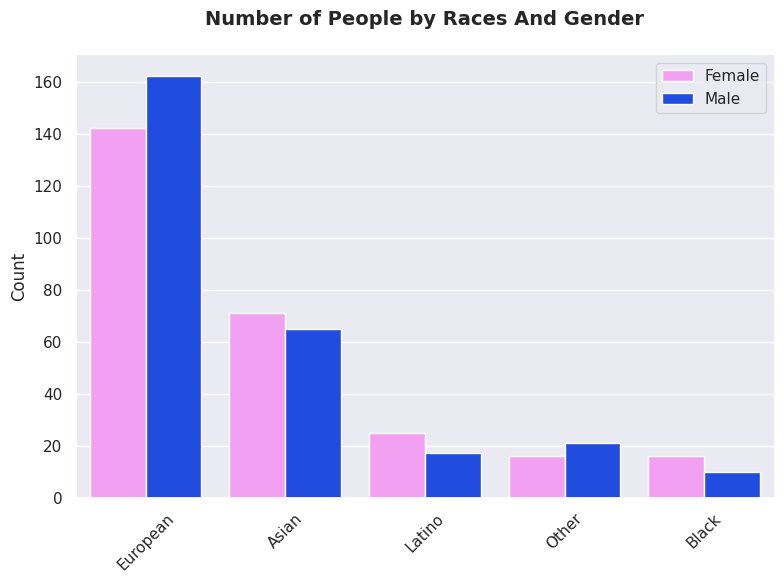

In [15]:
# -----------------------------------------------------------------------------
# RACE DISTRIBUTION
# -----------------------------------------------------------------------------
race_dict = {
    1 : 'Black',
	2 : 'European',
	3 : 'Latino',
	4 : 'Asian',
	5 : 'Native',
	6 : 'Other',
    }

tinder_df_race = tinder_df_raw.drop_duplicates(subset='iid').copy()
tinder_df_race = tinder_df_race[['iid', 'race', 'gender']]
tinder_df_race = (tinder_df_race
                  .groupby(['race', 'gender'])
                  .agg(count=('iid','count'))
                  .reset_index()
                  .sort_values(by='count', ascending=False)
                  )


tinder_df_race['race'] = tinder_df_race['race'].map(race_dict)
tinder_df_race['gender'] = tinder_df_race['gender'].map(gender_dict)


plt.figure(figsize=(8, 6))
ax = sns.barplot(data=tinder_df_race, 
            x='race',
            y='count',
            hue='gender',
            hue_order=['Female', 'Male'],
            palette=colors_sex, 
            alpha=1,
)

plt.title(f'Number of People by Races And Gender', fontsize=14, fontweight='bold', y=1.05)
plt.ylabel('Count')
plt.xlabel('')
plt.xticks(rotation=45)
legend = ax.get_legend()
if legend is not None:  # condition to suprpess pylance warning
    legend.set_title('')

sns.despine()       # Remove borders for cleaner look
plt.tight_layout()  # Adjust spacing
plt.show()

European participants dominate the dataset, followed by asians. Latinos, blacks and other categories are underrepresented while natives are simply just missing. The gender split is consistent across racial groups, reflecting the overall balanced gender ratio. This demographic skew is likely due to the university setting.

### D - Matches

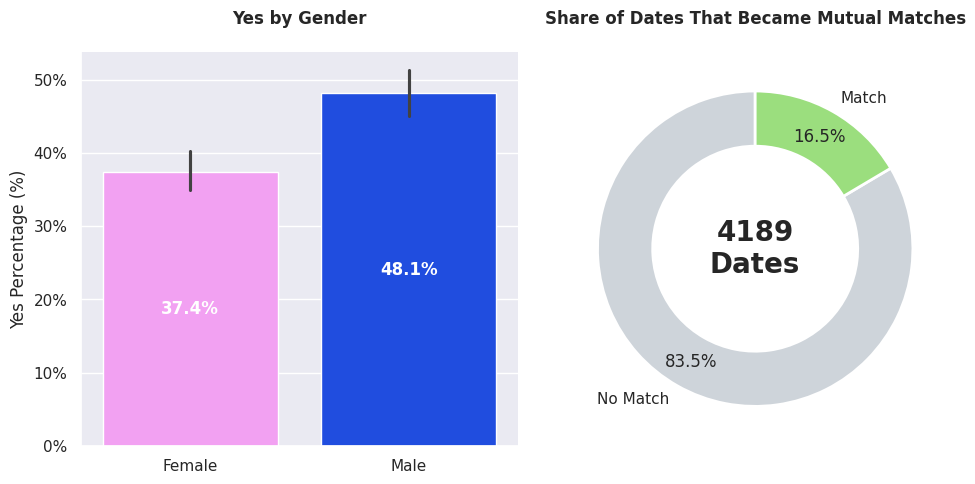

In [16]:
# -----------------------------------------------------------------------------
# MATCH BY GENDER
# -----------------------------------------------------------------------------
match_dict = {0: 'No Match', 1: 'Match'}


tinder_df_yes = tinder_df_normalized.copy()
tinder_df_yes = (
    tinder_df_yes
    .groupby('iid')
    .agg(gender=('gender', 'first'), 
         dec=('dec', 'mean'))
    .reset_index()
)

tinder_df_yes['gender'] = tinder_df_yes['gender'].map(gender_dict)

# -----------------------------------------------------------------------------
# MUTUAL MATCHES
# -----------------------------------------------------------------------------
tinder_df_match = tinder_df_normalized.copy()
tinder_df_match = (tinder_df_match
                   .groupby('match')['iid']
                   .count()
                   .to_frame(name='count')
                   .reset_index()
                   )
tinder_df_match['match'] = tinder_df_match['match'].map(match_dict)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(
    data=tinder_df_yes,
    x='gender',
    y='dec',
    hue='gender',
    palette=colors_sex,
    ax=axes[0],
    errorbar=('ci', 95),
)

# Add value labels on top of each bar
for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda x: f'{x*100:.1f}%', label_type='center', color='white', fontweight='bold')

axes[0].set_xlabel('')
axes[0].set_ylabel('Yes Percentage (%)')
axes[0].set_title('Yes by Gender', fontweight='bold', y=1.05)
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))   # Axis in %

axes[1].pie(tinder_df_match['count'], 
        labels=tinder_df_match['match'],
        startangle=90, 
        autopct='%1.1f%%',
        colors=['#ced4da', palette[5]],
        pctdistance=0.82,       # Move percentage into the donut chart
        wedgeprops={'width': 0.35, 'edgecolor': 'white', 'linewidth': 2}
        )

axes[1].text(
    0, 0,
    f"{(tinder_df_match['count'].sum()/2).astype(int)}\nDates",
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold'
)
axes[1].set_title('Share of Dates That Became Mutual Matches', fontweight='bold', y=1.05)

sns.despine()
plt.tight_layout()
plt.show()

Men say 'yes' more often than women, confirming that women are more selective in speed dating. Overall, mutual matches are rare, only a small fraction (`16.5%`) of dates result in both people saying 'yes'.

This low match rate underlines why understanding what actually drives attraction matters: most connections don't happen, and the ones that do require alignment from both sides.

### E - 'Yes' rate over time

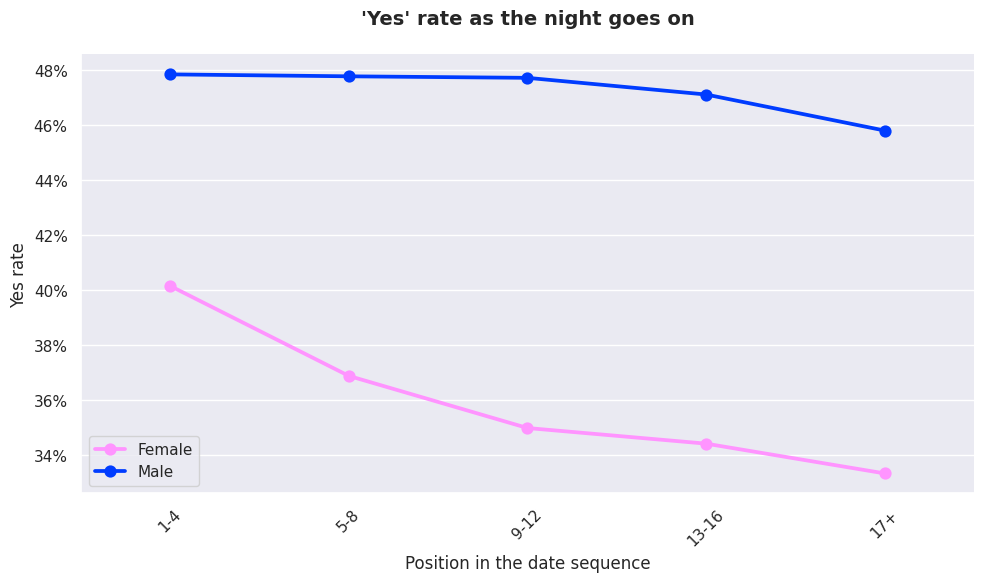

In [17]:
# -----------------------------------------------------------------------------
# ENTHOUSIASM
# -----------------------------------------------------------------------------
tinder_df_order = tinder_df_normalized[['order','dec','match','gender']].dropna(subset=['order','dec','match']).copy()
tinder_df_order['order'] = pd.cut(tinder_df_order['order'], 
                                    bins=[0,4,8,12,16,25],
                                    labels=['1-4','5-8','9-12','13-16','17+']
                                )
tinder_df_order = (tinder_df_order
                   .groupby(['order','gender'])['dec']
                   .mean()
                   .reset_index()
                )
tinder_df_order['gender'] = tinder_df_order['gender'].map(gender_dict)

plt.figure(figsize=(10, 6))
ax = sns.pointplot(data=tinder_df_order, 
            x='order',
            y='dec',
            hue='gender',
            palette=colors_sex, 
            alpha=1,
)

plt.title(f"'Yes' rate as the night goes on", fontsize=14, fontweight='bold', y=1.05)
plt.ylabel('Yes rate')
plt.xlabel('Position in the date sequence')
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0)) # yaxis legend formatting
ax.legend(title=None, loc='lower left')
sns.despine()       # Remove borders for cleaner look
plt.tight_layout()  # Adjust spacing
plt.show()

'Yes' rates tend to decline as the night progresses for both genders, suggesting decision fatigue: participants become more selective after meeting many people.

Women show a steeper and more consistent decline, while men's 'yes' rate is higher throughout but also drops over time. This order effect is worth noting: who you meet early in the evening may have a slight advantage.

### F - Stated gender preferences

In [18]:
# -----------------------------------------------------------------------------
# STATED PREFERENCES BY GENDER
# -----------------------------------------------------------------------------
categories = ['Attractiveness','Sincerity','Intelligence',
              'Fun', 'Ambition', 'Shared Interests']
categories.append(categories[0]) # Duplicate the first value so the radar chart can close up

colors_gender = ['#FF94FF', '#003CFF']

# Translate attributes name to proper name for cleaner legend
pref1_dict = {'attr1_1'   :   'Attractiveness',
               'sinc1_1'  :   'Sincerity',
               'intel1_1' :   'Intelligence',
               'fun1_1'   :   'Fun',
               'amb1_1'   :   'Ambition',
               'shar1_1'  :   'Shared Interests',
               }


tinder_df_pref_radar = tinder_df_normalized[['gender','attr1_1','sinc1_1','intel1_1','fun1_1','amb1_1','shar1_1']].copy()
tinder_df_pref_radar = (tinder_df_pref_radar
                  .groupby('gender')
                  .mean()
                  .reset_index()
                  .rename(columns=pref1_dict)
                  )
tinder_df_pref_radar['gender'] = tinder_df_pref_radar['gender'].map(gender_dict)
tinder_df_pref_radar = tinder_df_pref_radar.melt(id_vars='gender', 
                    value_vars=['Attractiveness', 'Sincerity', 'Intelligence', 
                                'Fun', 'Ambition', 'Shared Interests'], 
                    var_name='attributes')


fig = go.Figure()

for i, gender in enumerate(['Female', 'Male']):   # order must match colors_sex order: index 0 = Female, index 1 = Male
    sub = tinder_df_pref_radar[tinder_df_pref_radar['gender'] == gender].set_index('attributes').loc[categories]
    fig.add_trace(go.Scatterpolar(
        r=sub['value'],
        theta=categories,
        fill='toself',
        name=gender,
        line_color=colors_gender[i],
    ))


fig.update_layout(
    width=700,
    height=600,
    polar=dict(radialaxis=dict(visible=True)),
    margin=dict(l=10, r=10, t=40, b=10),
    showlegend=True,
    legend=dict(
        orientation='h',       # horizontal in a line
        yanchor='top',
        y=-0.1,                 # put the legend below the plotting area
        xanchor='center',
        x=0.5,                  # centered horizontally
    ),
    title=dict(
        text="Stated attributes Preferences by Gender",
        x=0.5,          # Center the title
        y=0.98,         # Let some space from the top of the layout
        font=dict(size=20)
    ),
    )

Men state that attractiveness is their top priority, allocating noticeably more weight to it. Women spread their preferences more evenly, valuing intelligence, sincerity, attractiveness and fun. Ambition and shared interests are rated noticeably lower for both gender.

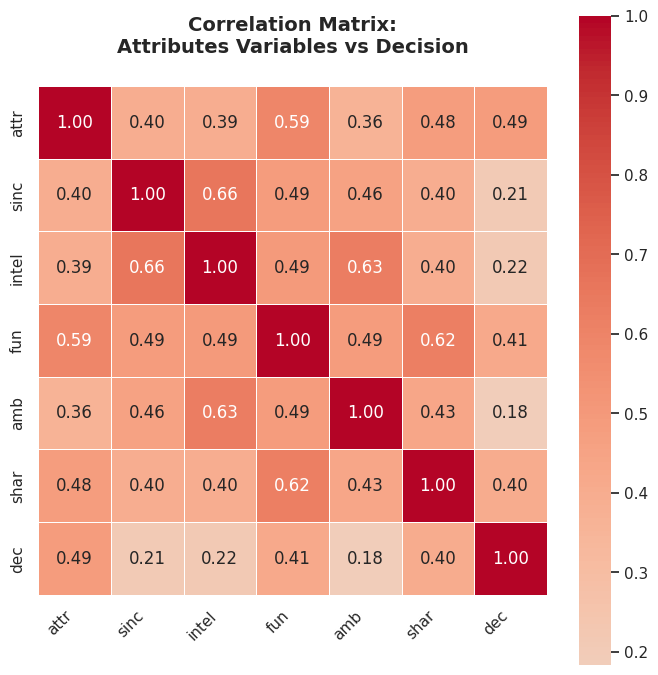

In [19]:
# -----------------------------------------------------------------------------
# CORRELATION MATRIX
# -----------------------------------------------------------------------------
metrics = ['gender','attr','sinc','intel','fun','amb','shar', 'dec']
tinder_df_corr = tinder_df_normalized.copy().loc[:,metrics].drop(columns='gender').corr()


fig, ax = plt.subplots(figsize=(7, 7))

sns.heatmap(tinder_df_corr, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm', 
            center=0,
            square=True, 
            linewidths=0.5, 
            ax=ax
            )
# Getting nice and clean x-axis, no legend colliding
ax.set_xticklabels(ax.get_xticklabels(),
                    rotation=45,
                    ha='right'
                    )
ax.set_title('Correlation Matrix:\nAttributes Variables vs Decision', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

Attractiveness shows the strongest positive correlation with the decision to say 'yes', confirming what the radar chart suggested. Fun and shared interests also correlate positively, while sincerity, intelligence, and ambition show weaker correlations with the decision.

The attributes themselves are slightly correlated with each other: someone rated high on one tends to be rated higher on others.

### G - Decisons ratings

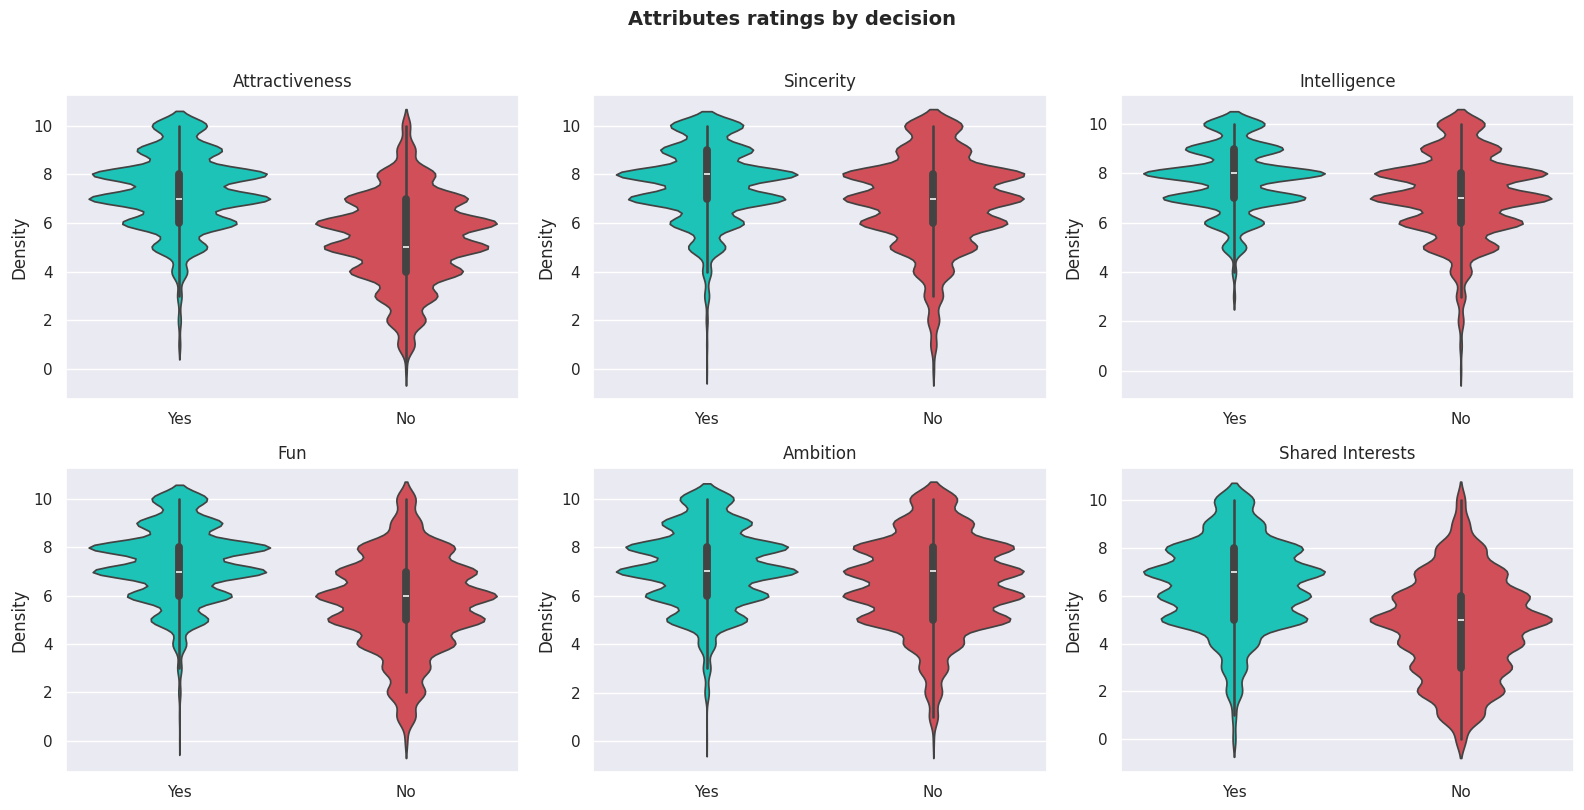

In [20]:
# -----------------------------------------------------------------------------
# RATINGS BY DECISONS
# -----------------------------------------------------------------------------

ratings = ["attr", "sinc", "intel", "fun", "amb", "shar"]

tinder_data_violin = tinder_df_normalized.copy()
tinder_data_violin['dec'] = tinder_data_violin['dec'].map({0: 'No', 1: 'Yes'})


fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, attribute, category in zip(axes, ratings, categories):

    sns.violinplot(
        data=tinder_data_violin,
        x="dec",
        y=attribute,
        hue="dec",
        palette={'Yes': decision_colors[0], 'No': decision_colors[1]},
        ax=ax
    )

    ax.set_title(category)
    ax.set_xlabel("")
    ax.set_ylabel("Density")

fig.suptitle(
    "Attributes ratings by decision",
    fontsize=14,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

Overall, partners receiving a 'yes' decision tend to have higher ratings across all attributes.

However, the distributions reveal that not all characteristics contribute equally to the decision:
- Attractiveness, fun and shared interests display stronger differences between accepted and rejected matches
- Sincerity, intelligence and ambition show more overlap

# 4 - Hypothesis testing

### 4.1 - Stated preferences by gender

In [21]:
# -----------------------------------------------------------------------------
# STATISTICAL TEST 1: DO MEN AND WOMEN HAVE DIFFERENT STATED PREFERENCES?
# -----------------------------------------------------------------------------

# Defining alpha as treshhold
alpha = 0.05

# Create a dataframe getting ratings per person (no duplicates)
tinder_df_pref = (
    tinder_df_normalized
    .groupby('iid')
    .agg(
        gender=('gender', 'first'),
        attr1_1=('attr1_1', 'first'),
        sinc1_1=('sinc1_1', 'first'),
        intel1_1=('intel1_1', 'first'),
        fun1_1=('fun1_1', 'first'),
        amb1_1=('amb1_1', 'first'),
        shar1_1=('shar1_1', 'first')
    )
    .reset_index()
)

test_list = [
        'Attractiveness',
        'Sincerity',
        'Intelligence',
        'Fun',
        'Ambition',
        'Shared Interests'
]

# FIRST: CHECKING ATTRIBUTE DISTRIBUTION TO CHOSE THE RIGHT TEST (PARAMETRIC VS NON-PARAMETRIC)
# H₀: The attributes distribution are normally distributed
# H₁: They aren't

# Checking if our attributes data distribution are normally distributed
attribute_distribution = []
for rating in before_date_ratings_1:
    male = tinder_df_pref[tinder_df_pref['gender'] == 1][rating].dropna()   # Droping na to avoid nan as result
    female = tinder_df_pref[tinder_df_pref['gender'] == 0][rating].dropna() # Droping na to avoid nan as result
    stat, p = shapiro(male)
    res_male = {'attributes': rating, 'sex': 'male', 'p-value': p}
    attribute_distribution.append(res_male)
    stat, p = shapiro(female)
    res_female = {'attributes': rating, 'sex': 'female', 'p-value': p}
    attribute_distribution.append(res_female)

attribute_distribution = pd.DataFrame(attribute_distribution)
attribute_distribution['result'] = attribute_distribution['p-value'].apply(
    lambda x: 'Reject H₀' if x < alpha else "don't reject H₀")
attribute_distribution['attributes'] = attribute_distribution['attributes'].map(pref1_dict)
attribute_distribution['p-value'] = attribute_distribution['p-value'].apply(
    lambda x: '< 0.001' if x < 0.001 else f'{x:.4f}')

print('H₀: The attributes distribution are normally distributed')
display(attribute_distribution)

H₀: The attributes distribution are normally distributed


,attributes,sex,p-value,result
0,Attractiveness,male,< 0.001,Reject H₀
1,Attractiveness,female,< 0.001,Reject H₀
2,Sincerity,male,< 0.001,Reject H₀
3,Sincerity,female,< 0.001,Reject H₀
4,Intelligence,male,< 0.001,Reject H₀
5,Intelligence,female,< 0.001,Reject H₀
6,Fun,male,< 0.001,Reject H₀
7,Fun,female,< 0.001,Reject H₀
8,Ambition,male,< 0.001,Reject H₀
9,Ambition,female,< 0.001,Reject H₀


The attributes distributions are not normally distributed:
We'll have to use Mann-Whitney U as an alternative to independant t-test.

In [22]:
# -----------------------------------------------------------------------------
# USING MANNWHITNEYU OVER INDEPENDANT T-TEST
# -----------------------------------------------------------------------------
# H₀: Men and women assign the same importance
# H₁: They don't

hypothesis_list = []

for rating, label in zip(before_date_ratings_1, test_list):
    male   = tinder_df_pref[tinder_df_pref['gender'] == 1][rating].dropna()
    female = tinder_df_pref[tinder_df_pref['gender'] == 0][rating].dropna()

    u, p_value = mannwhitneyu(male, female, alternative="two-sided")
    cohen_d = cohen_d_calc(male, female)


    hypothesis_list.append({
        'attributes':   label,
        'test_used':    'Mann-Whitney U',
        'U':            u,
        'p-value':      p_value,
        "cohen's d":    round(cohen_d, 3),
        'result':       'reject H₀' if p_value < alpha else "don't reject H₀"
    })

result1 = pd.DataFrame(hypothesis_list)
result1['p-value'] = result1['p-value'].apply(
    lambda x: '< 0.001' if x < 0.001 else f'{x:.4f}'
)

print('H₀: Men and women assign the same importance to the attribute')
display(result1)

H₀: Men and women assign the same importance to the attribute


,attributes,test_used,U,p-value,cohen's d,result
0,Attractiveness,Mann-Whitney U,56545.5,< 0.001,0.758,reject H₀
1,Sincerity,Mann-Whitney U,31190.0,0.0014,-0.263,reject H₀
2,Intelligence,Mann-Whitney U,34448.5,0.1590,-0.235,don't reject H₀
3,Fun,Mann-Whitney U,37883.0,0.5687,0.045,don't reject H₀
4,Ambition,Mann-Whitney U,22326.5,< 0.001,-0.714,reject H₀
5,Shared Interests,Mann-Whitney U,31496.0,0.0048,-0.275,reject H₀


A Mann–Whitney U test was conducted to compare men's and women's stated importance ratings because the normality assumption was not met.

The analysis reveals significant gender differences in ratings of attractiveness, sincerity, ambition, and shared interests (`p-value < 0.05`). Only fun and intelligence showed no significant difference in importance ratings.

Effect sizes vary considerably across these four significant attributes. Attractiveness (`d = 0.76`) and ambition (`d = -0.71`) show large effects: men state attractiveness matters substantially more, while women state ambition matters substantially more. Sincerity (`d = -0.26`) and shared interests (`d = -0.28`) show smaller, small-to-medium effects, both favoring women.

These results suggest that men and women not only differ in how they rate the importance of some partner attributes, but that these differences vary in magnitude, attractiveness and ambition stand out as far more gendered than sincerity or shared interests.

Men and women state different preferences, but stated preferences don't always predict behavior. The next question is whether men and women say 'yes' at the same rate.

### 4.2 - Decision rate by gender

In [23]:
# -----------------------------------------------------------------------------
# STATISTICAL TEST 2: DECISION RATE BY GENDER
# -----------------------------------------------------------------------------
person_yes_rate = (
    tinder_df_normalized
    .groupby('iid')
    .agg(gender=('gender', 'first'), 
         yes_rate=('dec', 'mean'))
    .reset_index()
)

male_rate = person_yes_rate[person_yes_rate['gender'] == 1]['yes_rate']
female_rate = person_yes_rate[person_yes_rate['gender'] == 0]['yes_rate']


# FIRST: CHECKING YES RATE DISTRIBUTION TO CHOSE THE RIGHT TEST (PARAMETRIC VS NON-PARAMETRIC)
# H₀: The rate distribution is normally distributed
# H₁: It's not


yes_rate_distribution = []

stat, p = shapiro(male_rate)
res_male = {'attributes': 'yes_rate', 'sex': 'male', 'p-value': p}
yes_rate_distribution.append(res_male)

stat, p = shapiro(female_rate)
res_female = {'attributes': 'yes_rate', 'sex': 'female', 'p-value': p}
yes_rate_distribution.append(res_female)

yes_rate_distribution = pd.DataFrame(yes_rate_distribution)
yes_rate_distribution['result'] = yes_rate_distribution['p-value'].apply(
    lambda x: 'reject H₀' if x < alpha else "don't reject H₀")
yes_rate_distribution['p-value'] = yes_rate_distribution['p-value'].apply(
    lambda x: '< 0.001' if x < 0.001 else f'{x:.4f}')

print('H₀: The rate distribution is normally distributed')
display(yes_rate_distribution)

H₀: The rate distribution is normally distributed


,attributes,sex,p-value,result
0,yes_rate,male,< 0.001,reject H₀
1,yes_rate,female,< 0.001,reject H₀


In [24]:
# -----------------------------------------------------------------------------
# USING MANNWHITNEYU OVER INDEPENDANT T-TEST
# -----------------------------------------------------------------------------
# H₀: Men and women say "yes" at the same rate
# H₁: They don't

# Metrics calculation
u, p_value2 = mannwhitneyu(male_rate, female_rate, alternative='two-sided')  # Compare distribution of personal yes-rates between genders
cohen_d = cohen_d_calc(male_rate, female_rate)
mean1, mean2 = np.mean(male_rate), np.mean(female_rate)

result2 = pd.DataFrame({
    'male mean yes_rate':   [round(mean1, 3)],
    'female mean yes_rate': [round(mean2, 3)],
    'p-value':              ['< 0.001' if p_value2 < 0.001 else f'{p_value2:.4f}'],
    "cohen's d":            [round(cohen_d, 3)],
    'result':               ['reject H₀' if p_value2 < alpha else "don't reject H₀"]
})

print("H₀: Men and women say 'yes' at the same rate")
display(result2)

H₀: Men and women say 'yes' at the same rate


,male mean yes_rate,female mean yes_rate,p-value,cohen's d,result
0,0.481,0.374,< 0.001,0.428,reject H₀


A Mann-Whitney U test was conducted to compare men's and women's personal 'yes' rates (aggregated per person, rather than per date, to avoid treating each individual's ~10-15 dates as independent observations) because the normality assumption was not met.

The test shows a statistically significant difference between men's and women's 'yes' rates (`p-value < 0.001`).
The effect size is small-to-medium (`d = 0.43`), smaller than the large gender gaps seen in stated importance for attractiveness and ambition (`d = 0.76` and `-0.71`), but larger than the small effects seen for sincerity and shared interests (`d = -0.26` and `-0.28`). This suggests gender explains a modest but non-trivial portion of the variation in actual decisions, though not as dramatically as it shapes people's stated priorities.

Men say 'yes' more often than women (`48.1%` vs. `37.4%`). This raises the question: are they also rating partners differently on the attributes that matter?

### 4.3 - Partner ratings by gender

In [25]:
# -----------------------------------------------------------------------------
# STATISTICAL TEST 3: DO MEN AND WOMEN RATE PARTNERS DIFFERENTLY?
# -----------------------------------------------------------------------------

rating_cols   = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']
rating_labels = ['Attractiveness', 'Sincerity', 'Intelligence', 'Fun', 'Ambition', 'Shared Interests']

person_ratings = (
    tinder_df_normalized
    .groupby('iid')
    .agg(gender=('gender', 'first'),
         **{col: (col, 'mean') for col in rating_cols})
    .reset_index()
)


# FIRST: CHECKING THE RATING DISTRIBUTION TO CHOSE THE RIGHT TEST (PARAMETRIC VS NON-PARAMETRIC)
# H₀: The rating distribution is normally distributed
# H₁: It's not


rating_distribution = []
for rating in rating_cols:
    male = person_ratings[person_ratings['gender'] == 1][rating].dropna()
    female = person_ratings[person_ratings['gender'] == 0][rating].dropna()

    stat, p = shapiro(male)
    rating_distribution.append({'attributes': rating, 'sex': 'male', 'p-value': p})

    stat, p = shapiro(female)
    rating_distribution.append({'attributes': rating, 'sex': 'female', 'p-value': p})

rating_distribution = pd.DataFrame(rating_distribution)
rating_distribution['result'] = rating_distribution['p-value'].apply(
    lambda x: 'reject H₀' if x < alpha else "don't reject H₀")
rating_distribution['p-value'] = rating_distribution['p-value'].apply(
    lambda x: '< 0.001' if x < 0.001 else f'{x:.4f}')

print('H₀: The rating distribution is normally distributed')
display(rating_distribution)

H₀: The rating distribution is normally distributed


,attributes,sex,p-value,result
0,attr,male,0.0036,reject H₀
1,attr,female,< 0.001,reject H₀
2,sinc,male,0.2836,don't reject H₀
3,sinc,female,0.0066,reject H₀
4,intel,male,0.2253,don't reject H₀
5,intel,female,0.1755,don't reject H₀
6,fun,male,0.0728,don't reject H₀
7,fun,female,0.0105,reject H₀
8,amb,male,0.4312,don't reject H₀
9,amb,female,0.1463,don't reject H₀


We'll use Mann-Whitney U for consistency with tests 1 and 2 since normality was violated for at least one gender on several attributes.

In [26]:
# -----------------------------------------------------------------------------
# USING MANNWHITNEYU OVER INDEPENDANT T-TEST
# -----------------------------------------------------------------------------
# H₀: Men and women give the same average rating for each attribute
# H₁: They don't

test3_results = []
for col, label in zip(rating_cols, rating_labels):
    male = person_ratings[person_ratings['gender'] == 1][col].dropna()
    female = person_ratings[person_ratings['gender'] == 0][col].dropna()

    # Metrics calculation
    u, p = mannwhitneyu(male, female, alternative='two-sided')
    cohen_d = cohen_d_calc(male, female)
    mean1, mean2 = np.mean(male), np.mean(female)

    test3_results.append({
        'attributes': label,
        'male mean': round(mean1, 3),
        'female mean': round(mean2, 3),
        'p-value': '< 0.001' if p < 0.001 else f'{p:.4f}',
        "cohen's d": round(cohen_d, 3),
        'result': 'reject H₀' if p < alpha else "don't reject H₀"
    })

result3 = pd.DataFrame(test3_results)

print('H₀: Men and women give the same average rating for each attribute')
display(result3)

H₀: Men and women give the same average rating for each attribute


,attributes,male mean,female mean,p-value,cohen's d,result
0,Attractiveness,6.471,5.927,< 0.001,0.500,reject H₀
1,Sincerity,7.287,7.137,0.2815,0.136,don't reject H₀
2,Intelligence,7.317,7.466,0.0324,-0.149,reject H₀
3,Fun,6.567,6.311,0.0328,0.230,reject H₀
4,Ambition,6.672,6.975,< 0.001,-0.270,reject H₀
5,Shared Interests,5.614,5.428,0.1875,0.139,don't reject H₀


A Mann-Whitney U test was used across all six attributes for consistency with the earlier tests, since normality was violated for at least one gender's distribution on several attributes.

Attractiveness, intelligence, fun, and ambition show significant gender differences in the ratings people give their partners (`p-value < 0.05`). Sincerity and shared interests do not (`p-value = 0.28` and `0.19` respectively).

Men rate partners higher on attractiveness (`d = 0.50`, medium effect) and fun (`d = 0.23`, small), women rate partners higher on ambition (`d = -0.27`, small-to-medium) and intelligence (`d = -0.15`, small). Attractiveness is by far the strongest and most reliable gender difference in ratings actually given.

This shows gendered patterns in how partners are evaluated, independent of whether those same attributes drive the decision to say yes.
Age proximity may play a separate role: we'll test that next.

### 4.4 - Age gap and matching

In [27]:
# -----------------------------------------------------------------------------
# STATISTICAL TEST 4: AGE GAP VS MATCH
# -----------------------------------------------------------------------------
# H₀: Matched and unmatched dates have the same age-gap distribution
# H₁: Matched pairs have a smaller age gap than unmatched pairs

# Each date appears twice in the raw data (once per partner's perspective)
# Deduplicating by creating a key pair to avoid double-counting each date
tinder_df_normalized['pair_key'] = (
    tinder_df_normalized[['iid', 'pid']].min(axis=1).astype(str) + '_' +
    tinder_df_normalized[['iid', 'pid']].max(axis=1).astype(str)
)

tinder_df_dates_pair = tinder_df_normalized.drop_duplicates(subset='pair_key')


tinder_df_dates_pair['age_gap'] = (tinder_df_dates_pair['age'] - tinder_df_dates_pair['age_o']).abs()
matched_age = tinder_df_dates_pair[tinder_df_dates_pair['match'] == 1]['age_gap'].dropna()
notmatched_age = tinder_df_dates_pair[tinder_df_dates_pair['match'] == 0]['age_gap'].dropna()

# Metrics calculation
stat4, p_value4 = mannwhitneyu(matched_age, notmatched_age, alternative='less')
mean1, mean2 = np.mean(matched_age), np.mean(notmatched_age)
cohen_d = cohen_d_calc(matched_age, notmatched_age)

result4 = pd.DataFrame([{
    'matched mean'  :   round(mean1, 2),
    'unmatched mean':   round(mean2, 2),
    'p-value'       :   '< 0.001' if p_value4 < 0.001 else f'{p_value4:.4f}',
    "cohen's d"     :   round(cohen_d, 3),
    'result'        :   'reject H₀' if p_value4 < alpha else "don't reject H₀"
}])

print('H₀: Matched and unmatched dates have the same age-gap distribution')
display(result4)

H₀: Matched and unmatched dates have the same age-gap distribution


,matched mean,unmatched mean,p-value,cohen's d,result
0,3.18,3.75,< 0.001,-0.187,reject H₀


A Mann-Whitney U test was conducted on age gap by match status, after deduplicating each date to a single row (the raw data stores every date twice, once from each partner's perspective).

Matched pairs have a significantly smaller age gap than unmatched pairs (`3.18` vs. `3.75` years, `p-value < 0.001)`.

However, the effect size is small (`d = -0.19`), suggesting that while age gap is associated with matching, the practical difference between the two groups is modest.

Closer in age means more likely to match, but the effect is small. Before moving to machine learning, we'll verify that missing data isn't biasing our results.

### 4.5 - Missing values

We'll divide the population into 3 groups: fully complete, partially missing and fully missing.
We'll compare both the missing groups to the fully complete one.

In [28]:
# -----------------------------------------------------------------------------
# STATISTICAL TEST 5: MISSING VALUES AND 'YES' RATE
# -----------------------------------------------------------------------------
# H₀: The decision ('yes'/'no') is independent of missingness group
# H₁: It isn't

col_missing_data = rating_cols + ['dec']
tinder_missing_df = tinder_df_raw[col_missing_data].copy()
tinder_missing_df['n_missing'] = tinder_missing_df[rating_cols].isna().sum(axis=1)

def missing_group(n: int) -> str:
    if n == 0:
        return 'complete'
    elif n < 6:
        return 'partial'
    else:
        return 'all_missing'

tinder_missing_df['group'] = tinder_missing_df['n_missing'].apply(missing_group)
tinder_missing_df.drop(columns=rating_cols + ['n_missing'], inplace=True) # Dropping to keep only the group type and dec

# First test:
# H₀: Complete and partially-missing rows have the same 'yes' rate

# Metrics calculation
crosstab_a = pd.crosstab(tinder_missing_df[tinder_missing_df['group'] != 'all_missing']['dec'],
                     tinder_missing_df[tinder_missing_df['group'] != 'all_missing']['group'])
chi2_a, p_value_a, dof_a, exp_a = chi2_contingency(crosstab_a)
n_a = crosstab_a.values.sum()
cramer_v_a = np.sqrt(chi2_a / (n_a * min(crosstab_a.shape[0]-1, crosstab_a.shape[1]-1)))

result_a = {
    'group': 'partially-missing',
    'p-value': '< 0.001' if p_value_a < 0.001 else f'{p_value_a:.4f}', # type: ignore
    'chi2': chi2_a,
    'cramer v': cramer_v_a,
    'result': 'reject H₀' if p_value_a < alpha else "don't reject H₀" # type: ignore
}

# Second test:
# H₀: Complete and fully-missing rows have the same 'yes' rate
crosstab_b = pd.crosstab(tinder_missing_df[tinder_missing_df['group'] != 'partial']['dec'],
                     tinder_missing_df[tinder_missing_df['group'] != 'partial']['group'])

# Metrics calculation
chi2_b, p_value_b, dof_b, exp_b = chi2_contingency(crosstab_b)
n_b = crosstab_b.values.sum()
cramer_v_b = np.sqrt(chi2_b / (n_b * min(crosstab_b.shape[0]-1, crosstab_b.shape[1]-1)))

result_b = {
    'group': 'fully-missing',
    'p-value': '< 0.001' if p_value_b < 0.001 else f'{p_value_b:.4f}', # type: ignore
    'chi2': chi2_b,
    'cramer v': cramer_v_b,
    'result': 'reject H₀' if p_value_b < alpha else "don't reject H₀" # type: ignore
}


# Descriptive breakdown by missingness group
missing_summary = (tinder_missing_df
                   .groupby('group')['dec']
                   .agg(
                    n='count', 
                    yes_rate='mean')
                    .reset_index()
                    .sort_values(
                        by='yes_rate', 
                        ascending=False)
)


missing_summary['yes_rate'] = (missing_summary['yes_rate'] * 100).round(1).astype(str) + '%'
print('Summary of groups by missing values')
display(missing_summary)

result5 = pd.DataFrame([result_a, result_b])
print("\nH₀: The decision ('yes'/'no') is independent of missingness group")
display(result5)

Summary of groups by missing values


,group,n,yes_rate
1,complete,7040,43.1%
2,partial,1146,41.5%
0,all_missing,192,3.1%



H₀: The decision ('yes'/'no') is independent of missingness group


,group,p-value,chi2,cramer v,result
0,partially-missing,0.3291,0.952304,0.010786,don't reject H₀
1,fully-missing,< 0.001,121.073875,0.129389,reject H₀


To evaluate the modeling approach, rows are split into three groups based on missing ratings: 
* fully complete (n=7040)
* partially missing (n=1146)
* fully missing (n=192)

Partially missing and fully missing groups are both compared to the complete group with a chi-square test.

**Complete and partially-missing rows:**
There's no significant difference in 'yes' rate (`p-value = 0.329`, `Cramér's V = 0.011`), supporting mean imputation as a reasonable choice for these rows, since they behave statistically like complete data.

**Complete and fully-missing rows:**
There's a highly significant difference (`p-value < 0.001`, `Cramér's V = 0.129`), with the fully-missing group's yes-rate dropping to `3.1%` versus `43.1%` for complete rows. This extreme, one-sided gap suggests these rows likely represent dates that didn't take place or weren't recorded, rather than genuine 'no' decisions, justifying their exclusion from the model.

# 5 - Machine learning

## 5.1 - Settings

Based on previous analysis, we drop rows where all 6 rating attributes
are missing: those carry no information for the models.

In [29]:
# -----------------------------------------------------------------------------
# DROPPING ROWS AND CREATING 1 DATASET PER GENDER
# -----------------------------------------------------------------------------
all_missing_mask = tinder_df_normalized[rating_cols].isna().all(axis=1)
tinder_df_model = tinder_df_normalized[~all_missing_mask].copy()
print(f'Rows dropped: {all_missing_mask.sum()} | Rows for modelling: {len(tinder_df_model)}')


# Separate target variable Y from features X
print("Separating labels from features...")
features_list = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']
target_variable = 'dec'


# Creating 2 datasets, one for women, one for men to analyze the differences between genders
tinder_df_normalized_female = tinder_df_model.loc[tinder_df_model['gender'] == 0,:]
tinder_df_normalized_male = tinder_df_model.loc[tinder_df_model['gender'] == 1,:]

Rows dropped: 192 | Rows for modelling: 8186
Separating labels from features...


## 5.2 - Females

### A - Female ML model

In [30]:
# -----------------------------------------------------------------------------
# TRAIN TEST SPLIT
# -----------------------------------------------------------------------------
X = tinder_df_normalized_female.loc[:,features_list]
Y = tinder_df_normalized_female.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.15, random_state=0)
print("...Done.")
print()


# -----------------------------------------------------------------------------
# PIPELINE
# -----------------------------------------------------------------------------
# Create pipeline for numeric features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Use ColumnTranformer to make a preprocessor object that describes all the treatments to be done
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_list),
    ])


# Preprocessings on train set
print("Performing preprocessings on train set...")
print(X_train.head()) # type: ignore
X_train = preprocessor.fit_transform(X_train)
print('...Done.')
print(X_train[0:5,:]) # type: ignore
print()

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head())
X_test = preprocessor.transform(X_test) # Don't fit again !!
print('...Done.')
print(X_test[0:5,:]) # type: ignore
print()


# -----------------------------------------------------------------------------
# TRAINING
# -----------------------------------------------------------------------------
# Train model
model = LogisticRegression()

print("Training model...")
model.fit(X_train, Y_train) # Training is always done on train set !!
print("...Done.")
print()

# -----------------------------------------------------------------------------
# PREDICTIONS
# -----------------------------------------------------------------------------
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = model.predict(X_train)
print("...Done.")
print(Y_train_pred[0:5])
print()

# Predictions on test set
print("Predictions on test set...")
Y_test_pred = model.predict(X_test)
print("...Done.")
print(Y_test_pred[0:5])
print()


# -----------------------------------------------------------------------------
# METRICS EXPORT
# -----------------------------------------------------------------------------
# Exporting female model metrics
metrics_female, features_female, cms_female = model_report(Y_train, Y_test, Y_train_pred, Y_test_pred, model, preprocessor, 'Female')

...Done.

Y : 
0    1
1    1
2    1
3    1
4    1
Name: dec, dtype: int64

X :
   attr  sinc  intel  fun  amb  shar
0   6.0   9.0    7.0  7.0  6.0   5.0
1   7.0   8.0    7.0  8.0  5.0   6.0
2   5.0   8.0    9.0  8.0  5.0   7.0
3   7.0   6.0    8.0  7.0  6.0   8.0
4   5.0   6.0    7.0  7.0  6.0   6.0
Dividing into train and test sets...
...Done.

Performing preprocessings on train set...
      attr  sinc  intel   fun   amb  shar
92     6.0  10.0   10.0  10.0   6.0   NaN
7013   6.0   3.0    8.0   6.0   5.0   5.0
3770   3.0   5.0    6.0   5.0   4.0   3.0
2785   6.0   8.0    8.0   9.0   8.0   6.0
5112   5.0  10.0    8.0   5.0  10.0   5.0
...Done.
[[ 0.03450425  1.55640742  1.56602328  1.8259783  -0.54599566  0.        ]
 [ 0.03450425 -2.2130547   0.32370819 -0.14744014 -1.1107047  -0.20029513]
 [-1.46480977 -1.13606552 -0.91860689 -0.64079475 -1.67541374 -1.16758563]
 [ 0.03450425  0.47941824  0.32370819  1.33262369  0.58342243  0.28335011]
 [-0.46526709  1.55640742  0.32370819 -0.64079475

### B - Dummy female model

In [31]:
# -----------------------------------------------------------------------------
# DUMMY FEMALE MODEL
# -----------------------------------------------------------------------------

# Dummy female model
baseline = DummyClassifier(strategy='most_frequent', random_state=0)    # Predict decision = 'no' every single time
baseline.fit(X_train, Y_train)
Y_train_pred_baseline = baseline.predict(X_train)
Y_test_pred_baseline = baseline.predict(X_test)


# Exporting dummy female model metrics
dummy_female_metrics, _, dummy_female_conf_matrix = model_report(Y_train, 
                                                                    Y_test, 
                                                                    Y_train_pred_baseline, 
                                                                    Y_test_pred_baseline, 
                                                                    'dummy', 
                                                                    None, 
                                                                    'Female')

## 5.3 - Males

### A - Male ML model

In [32]:
# -----------------------------------------------------------------------------
# TRAIN TEST SPLIT
# -----------------------------------------------------------------------------
X = tinder_df_normalized_male.loc[:,features_list]
Y = tinder_df_normalized_male.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.15, random_state=0)
print("...Done.")
print()


# -----------------------------------------------------------------------------
# PIPELINE
# -----------------------------------------------------------------------------
# Create pipeline for numeric features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Use ColumnTranformer to make a preprocessor object that describes all the treatments to be done
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_list),
    ])


# Preprocessings on train set
print("Performing preprocessings on train set...")
print(X_train.head()) # type: ignore
X_train = preprocessor.fit_transform(X_train)
print('...Done.')
print(X_train[0:5,:]) # type: ignore
print()

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head())
X_test = preprocessor.transform(X_test) # Don't fit again !!
print('...Done.')
print(X_test[0:5,:]) # type: ignore
print()


# -----------------------------------------------------------------------------
# TRAINING
# -----------------------------------------------------------------------------
# Train model
model = LogisticRegression()

print("Training model...")
model.fit(X_train, Y_train) # Training is always done on train set !!
print("...Done.")
print()

# -----------------------------------------------------------------------------
# PREDICTIONS
# -----------------------------------------------------------------------------
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = model.predict(X_train)
print("...Done.")
print(Y_train_pred[0:5])
print()

# Predictions on test set
print("Predictions on test set...")
Y_test_pred = model.predict(X_test)
print("...Done.")
print(Y_test_pred[0:5])
print()



# -----------------------------------------------------------------------------
# METRICS EXPORT
# -----------------------------------------------------------------------------
# Exporting male model metrics
metrics_male, features_male, cms_male = model_report(Y_train, Y_test, Y_train_pred, Y_test_pred, model, preprocessor, 'Male')

...Done.

Y : 
100    0
101    0
102    0
103    0
104    0
Name: dec, dtype: int64

X :
     attr  sinc  intel  fun  amb  shar
100   6.0   8.0    8.0  8.0  8.0   6.0
101   8.0   7.0    6.0  9.0  7.0   4.0
102   7.0   8.0    6.0  5.0  8.0   4.0
103   6.0   7.0    8.0  7.0  7.0   5.0
104   6.0   8.0    8.0  8.0  7.0   6.0
Dividing into train and test sets...
...Done.

Performing preprocessings on train set...
      attr  sinc  intel   fun  amb  shar
1002   5.0   6.0    7.0   6.0  5.0   5.0
4958   6.0   8.0    8.0   8.0  6.0   7.0
3177   8.0   5.0    6.0   7.0  6.0   3.0
6343   8.0   9.0    7.0  10.0  5.0   5.0
4940  10.0  10.0    9.0  10.0  9.0   9.0
...Done.
[[-0.78230237 -0.78632947 -0.20012464 -0.2834349  -0.95394669 -0.27544704]
 [-0.24147515  0.46317044  0.47632811  0.81198111 -0.35840139  0.72771151]
 [ 0.84017928 -1.41107943 -0.8765774   0.2642731  -0.35840139 -1.27860559]
 [ 0.84017928  1.0879204  -0.20012464  1.90739712 -0.95394669 -0.27544704]
 [ 1.92183372  1.71267036  1.1527

### B - Dummy male model

In [33]:
# -----------------------------------------------------------------------------
# DUMMY MALE MODEL
# -----------------------------------------------------------------------------

# Dummy male model
baseline = DummyClassifier(strategy='most_frequent', random_state=0)    # Predict decision = 'no' every single time
baseline.fit(X_train, Y_train)
Y_train_pred_baseline = baseline.predict(X_train)
Y_test_pred_baseline = baseline.predict(X_test)


# Exporting dummy female model metrics
dummy_male_metrics, _, dummy_male_conf_matrix = model_report(Y_train, 
                                                                    Y_test, 
                                                                    Y_train_pred_baseline, 
                                                                    Y_test_pred_baseline, 
                                                                    'dummy', 
                                                                    None, 
                                                                    'Male')

## 5.4 - Women vs men comparison

### A - Setup and merging results

In [34]:
# -----------------------------------------------------------------------------
# MERGING RESULTS
# -----------------------------------------------------------------------------
# Reminder:
# - Precision  % of predicted 'yes', how many were actually 'yes'
# - Recall     % of actual 'yes', how many did the model catch
# - F1-score   harmonic mean of precision and recall

features_dict = {'num__attr'    :   'Attractiveness',
               'num__sinc'      :   'Sincerity',
               'num__intel'     :   'Intelligence',
               'num__fun'       :   'Fun',
               'num__amb'       :   'Ambition',
               'num__shar'      :   'Shared Interests',
               }

# ML models
metrics = pd.concat([metrics_female, metrics_male]) # Merge women and men ML scores together
feature_importance_combined = pd.concat([features_female, features_male]) # Merge women and men features importances together
feature_importance_combined['feature'] = feature_importance_combined['feature'].map(features_dict) # For cleaner result


# Dummy models
dummy_metrics = pd.concat([dummy_female_metrics, dummy_male_metrics])   # Merge women and men dummy scores together

### B - Metrics and confusion matrix

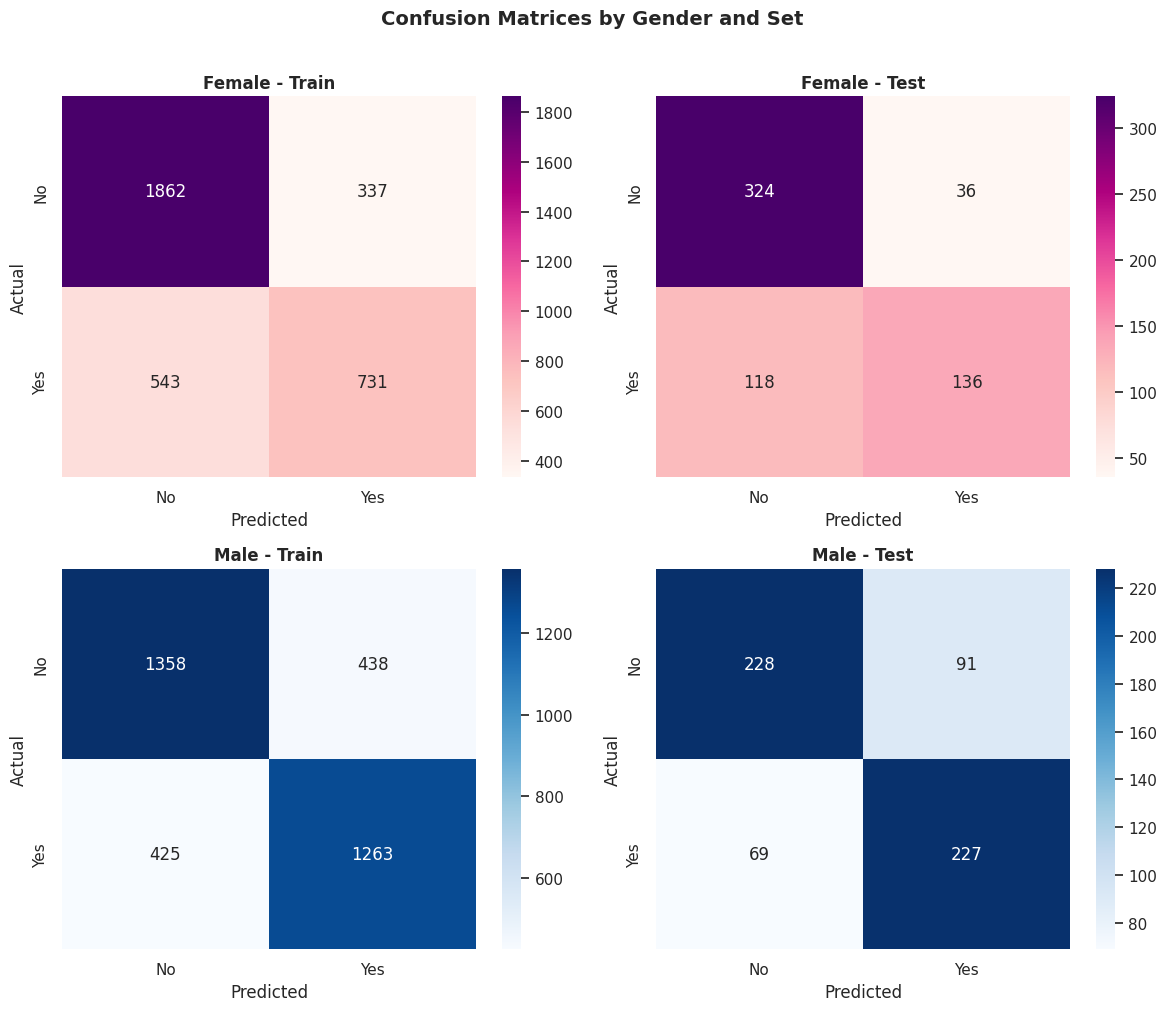


Result summary:


,gender,set,accuracy,precision,recall,f1-score
0,Female,train,0.746617,0.729339,0.710266,0.716557
1,Female,test,0.749186,0.761865,0.717717,0.723239
0,Male,train,0.752296,0.752071,0.752174,0.752112
1,Male,test,0.739837,0.740757,0.740813,0.739837



Dummy summary:


,gender,set,accuracy,precision,recall,f1-score
0,Female,train,0.633170,0.316585,0.5,0.387694
1,Female,test,0.586319,0.293160,0.5,0.369610
0,Male,train,0.515499,0.257750,0.5,0.340152
1,Male,test,0.518699,0.259350,0.5,0.341542


In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (cms, gender) in enumerate([(cms_female, 'Female'), (cms_male, 'Male')]):
    for col, split in enumerate(['train', 'test']):
        sns.heatmap(
            cms[split],
            annot=True,
            fmt='d',
            cmap='Blues' if gender == 'Male' else 'RdPu',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'],
            ax=axes[row, col]
        )
        axes[row, col].set_xlabel('Predicted')
        axes[row, col].set_ylabel('Actual')
        axes[row, col].set_title(f'{gender} - {split.capitalize()}', fontweight='bold')

plt.suptitle('Confusion Matrices by Gender and Set', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print(f'\nResult summary:')
display(metrics)

print(f'\nDummy summary:')
display(dummy_metrics)

Both models substantially outperform a baseline (female: F1 `0.72` vs. `0.37`, male: F1 `0.74` vs. `0.34`), confirming the six attribute ratings carry real predictive signal.

Train/test gaps are small for both genders, indicating no overfitting.

The male model shows slightly higher raw performance (F1 `0.74` vs. `0.72`) and since its baseline is lower (`0.34` vs. `0.37`), that means the male model's ratings have more predicting power.

Beyond the metrics, the confusion matrices reveal a meaningful asymmetry:
* The female model correctly identifies 'no' decisions `90%` of the time on test but only catches `53.5%` of actual 'yes', suggesting it remains somewhat biased toward the majority class.
* The male model is more balanced (`71.5%` vs. `76.7%`), correctly identifying both outcomes at similar rates. This suggests attraction may be more predictable for men than for women in this dataset.

Either way, the goal here isn't to build a flawless model, but to get which features matter most for predicting women's and men's decisions.
That's why we'll see next.

### C - Features importance differences

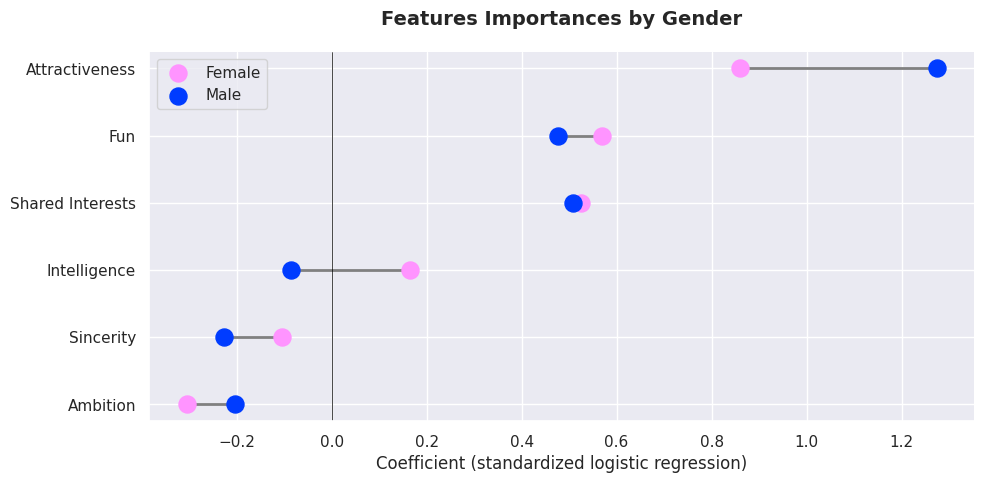

In [36]:
# -----------------------------------------------------------------------------
# FEATURES IMPORTANCE
# -----------------------------------------------------------------------------
# Pivot dataframe: each feature has one Female and one Male value side-by-side
pivoted = feature_importance_combined.pivot(index='feature', columns='gender', values='coefficient')
pivoted = pivoted.loc[pivoted.mean(axis=1).sort_values(ascending=True).index]  # sort by avg importance

fig, ax = plt.subplots(figsize=(10, 5))

# Line between each Female/Male pair
for feat in pivoted.index:
    ax.plot([pivoted.loc[feat, 'Female'],   # type: ignore
            pivoted.loc[feat, 'Male']],     # type: ignore
            [feat, feat], 
            color='gray', 
            linewidth=2, 
            zorder=1
            )

# Dots
ax.scatter(pivoted['Female'], 
           pivoted.index, 
           color=colors_sex[0], 
           s=150, 
           label='Female', 
           zorder=3
           )

ax.scatter(pivoted['Male'], 
           pivoted.index, 
           color=colors_sex[1], 
           s=150, 
           label='Male', 
           zorder=3
           )

ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('Coefficient (standardized logistic regression)')
ax.set_title('Features Importances by Gender', fontsize=14, fontweight='bold', y=1.05)
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

Feature importance reveals that the main predictors of dating decisions are consistent between men and women. The same attributes contribute most to the model predictions, supporting the earlier observation that attractiveness, fun, and shared interests provide stronger signals for a positive decision. This suggests that, despite potential differences in individual preferences, the key predictive factors are largely shared across genders.

### D - Conclusion

This analysis aims to answer one question: **what drives a match?**

**Attractiveness** emerges as the most consistent driver of interest across every stage of this analysis:
* Significant in stated importance (*test 1*)
* By far the strongest predictor of an actual 'yes' in the logistic regression, for both men (`coefficient = 1.27`) and women (`0.86`)

It is the closest thing to a **universal factor** in this dataset.

**Fun** and **shared interests** are the next two biggest drivers of an actual 'yes' (coefficients bewteen `0.48` and `0.57` for both), and this is where the gap between what people say and what they do shows up most sharply. In stated importance (*test 1*), shared interests ranks *last* for women and second-to-last for men, the attribute both genders claim to care about least. Yet in the model, it's tied for the second-strongest predictor of an actual match for both genders, just behind attractiveness. People seem to underrate how much shared interests actually shapes their decisions.

The results also reveal some differences between men and women. Attractiveness shows the largest gender gap of any attribute in the ratings people actually give partners (*test 3*, `d = 0.50`), meaning men and women evaluate this attribute differently on average, despite it having a similarly strong influence on their final decisions.

 Men also give higher ratings on fun, women give higher ratings on intelligence and ambition (*test 3*), and men say 'yes' more often overall (*test 2*, `48.1%` vs. `37.4%`).
 
Age similarity has a smaller but measurable effect: closer-in-age pairs are slightly more likely to match, although the effect size is limited (*test 4*, `d = 0.19`).

Overall, the analysis shows that what people report valuing and what actually drives their decisions are not always the same. **Attractiveness** consistently dominates predictions for both genders, while **fun** and **shared interests** emerge as important secondary factors. Most importantly, shared interests illustrate the largest gap between stated preferences and actual behavior: **people may claim it matters less, but their decisions suggest otherwise**.